# 02. Ni·Co 회수율 모델 비교와 고정 상태 재현

**목표:** 동일한 바깥 검증 fold에서 비교 후보의 MAE/RMSE를 확인하고, alpha 선택·OOF 예측·중요도·재학습 상태를 살펴봅니다.

모델 비교는 개발 357행 내부의 순서 보존 확장 창입니다. 예약 63행은 평가에서 제외하며, 이미 확인된 자료라 새 blind test가 아닙니다. `train_final()`은 별도 재현 상태를 저장하고, `Engine()`의 고정 추론 모델을 자동 교체하지 않습니다.

In [1]:
from pathlib import Path
import sys
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# 저장소 내부의 어디에서 열어도 루트를 찾습니다. 개인·절대 경로는 사용하지 않습니다.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents)
             if (p / "module1_preprocessing").is_dir()
             and (p / "module2_prediction").is_dir()
             and (p / "module3_optimization").is_dir()), None)
if ROOT is None:
    raise RuntimeError("저장소 전체를 가져온 뒤 저장소 루트 또는 notebooks 폴더에서 실행하세요.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 24)
pd.set_option("display.precision", 6)
print({"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__})

{'python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3'}


## 1. 동일 프로토콜 평가 실행

비교 후보는 baseline, ridge11, curve17, bounded17, interaction20입니다. 바깥 학습/검증은 90/89, 179/89, 268/89이며, 각 학습 구간 내부 3-fold에서 alpha 0.1·1·10·100을 원래 회수율 단위의 MAE로 선택합니다. 결측 보간·표준화도 fold 내부에서 적합합니다.

In [2]:
from module2_prediction.evaluate import evaluate_models
from module2_prediction.train import train_final
from module2_prediction.importance import run_importance
from module2_prediction.inference import Engine
from module1_preprocessing.pipeline import load_clean_data
from module1_preprocessing.schema import BASE
from module1_preprocessing.features import feature_matrix

evaluation = evaluate_models()
RESULTS = Path(evaluation["output_dir"])
metrics = pd.read_csv(RESULTS / "metrics.csv")
folds = pd.read_csv(RESULTS / "fold_metrics.csv")
oof = pd.read_csv(RESULTS / "oof_predictions.csv")
tuning = pd.read_csv(RESULTS / "tuning_results.csv")
display(metrics[["Metal", "Candidate", "N", "MAE", "RMSE", "R2", "P90_abs", "Max_abs", "Bias"]])
display(folds.loc[folds["Candidate"].eq("curve17"),
                  ["Metal", "Fold", "TrainN", "ValidN", "Alpha", "MAE", "RMSE", "TrainMAE", "MAE_gap"]])

,Metal,Candidate,N,MAE,RMSE,R2,P90_abs,Max_abs,Bias
0,Ni,baseline,267,1.872871,2.328829,0.842289,3.633418,6.545097,-0.176332
1,Ni,ridge11,267,1.955064,2.405085,0.831792,3.946413,6.435824,-0.256158
2,Ni,curve17,267,1.741881,2.196502,0.859702,3.566841,7.002785,-0.186885
3,Ni,bounded17,267,2.199302,2.742255,0.781323,4.379468,9.109187,0.100823
4,Ni,interaction20,267,1.756510,2.206910,0.858370,3.546973,7.058581,-0.173377
5,Co,baseline,267,2.079797,2.685718,0.843141,4.505762,8.958931,0.133124
6,Co,ridge11,267,2.079797,2.685718,0.843141,4.505762,8.958931,0.133124
7,Co,curve17,267,1.905236,2.519481,0.861958,4.366468,8.600306,0.204193
8,Co,bounded17,267,2.001817,2.620013,0.850722,4.391810,8.309882,0.390573
9,Co,interaction20,267,1.951368,2.560056,0.857476,4.290823,8.352382,0.153536


,Metal,Fold,TrainN,ValidN,Alpha,MAE,RMSE,TrainMAE,MAE_gap
2,Ni,1,90,89,1.0,1.642625,2.051351,1.486253,0.156372
7,Ni,2,179,89,0.1,1.793373,2.262603,1.440684,0.352689
12,Ni,3,268,89,0.1,1.789645,2.268579,1.504724,0.284920
17,Co,1,90,89,1.0,1.840926,2.437578,1.808282,0.032644
22,Co,2,179,89,0.1,1.847780,2.407017,1.700906,0.146874
27,Co,3,268,89,1.0,2.027002,2.703302,1.738439,0.288563


In [3]:
selected_tuning = tuning.loc[tuning["Selected"].astype(str).str.lower().eq("true")]
display(selected_tuning[["Scope", "OuterFold", "InnerFold", "Metal", "Candidate", "Alpha",
                         "TrainN", "ValidN", "MAE", "PooledInnerMAE"]].head(30))
display(tuning.groupby(["Metal", "Candidate", "Alpha"], sort=False).size().rename("inner_fold_records").to_frame())

,Scope,OuterFold,InnerFold,Metal,Candidate,Alpha,TrainN,ValidN,MAE,PooledInnerMAE
0,outer,1,1,Ni,ridge11,0.1,24,22,1.855312,1.990199
1,outer,1,2,Ni,ridge11,0.1,46,22,2.388254,1.990199
2,outer,1,3,Ni,ridge11,0.1,68,22,1.727032,1.990199
15,outer,1,1,Ni,curve17,1.0,24,22,2.124263,2.052609
16,outer,1,2,Ni,curve17,1.0,46,22,2.408905,2.052609
17,outer,1,3,Ni,curve17,1.0,68,22,1.624657,2.052609
27,outer,1,1,Ni,bounded17,1.0,24,22,2.397389,2.393045
28,outer,1,2,Ni,bounded17,1.0,46,22,2.399244,2.393045
29,outer,1,3,Ni,bounded17,1.0,68,22,2.382501,2.393045
39,outer,1,1,Ni,interaction20,1.0,24,22,2.194647,2.098619


inner_fold_records
Metal Candidate     Alpha                    
Ni    ridge11       0.1                     9
                    1.0                     9
                    10.0                    9
                    100.0                   9
      curve17       0.1                     9
                    1.0                     9
                    10.0                    9
                    100.0                   9
      bounded17     0.1                     9
                    1.0                     9
                    10.0                    9
                    100.0                   9
      interaction20 0.1                     9
                    1.0                     9
                    10.0                    9
                    100.0                   9
Co    ridge11       0.1                     9
                    1.0                     9
                    10.0                    9
                    100.0                   9
      curve17       0.1                     9
                    1.0                     9
                    10.0                    9
                    100.0                   9
      bounded17     0.1                     9
                    1.0                     9
                    10.0                    9
                    100.0                   9
      interaction20 0.1                     9
                    1.0                     9
                    10.0                    9
                    100.0                   9

## 2. OOF 예측에서 MAE와 RMSE를 직접 재계산

검증 대상 관측을 학습하지 않은 바깥 fold 예측을 모아 계산합니다. MAE·RMSE는 %p 단위입니다. pooled RMSE와 fold RMSE의 단순 평균은 같은 값이 아닐 수 있습니다.

In [4]:
curve_oof = oof.loc[oof["Candidate"].eq("curve17")].copy()
recomputed = []
for metal, group in curve_oof.groupby("Metal", sort=False):
    error = group["Predicted"].to_numpy() - group["Actual"].to_numpy()
    recomputed.append({"Metal": metal, "N": len(error), "MAE": np.abs(error).mean(),
                       "RMSE": np.sqrt(np.mean(error**2)), "Bias": error.mean()})
recomputed = pd.DataFrame(recomputed)
display(recomputed)
for _, row in recomputed.iterrows():
    reference = metrics.loc[metrics["Metal"].eq(row["Metal"]) & metrics["Candidate"].eq("curve17")].iloc[0]
    np.testing.assert_allclose(row[["MAE", "RMSE"]].to_numpy(float),
                               reference[["MAE", "RMSE"]].to_numpy(float), atol=1e-12)
display(curve_oof[["Metal", "Fold", "BatchID", "Actual", "Predicted", "Residual", "AbsoluteError"]].head(10))

,Metal,N,MAE,RMSE,Bias
0,Ni,267,1.741881,2.196502,-0.186885
1,Co,267,1.905236,2.519481,0.204193


,Metal,Fold,BatchID,Actual,Predicted,Residual,AbsoluteError
178,Ni,1,BP-2025-0091,82.09,82.868677,0.778677,0.778677
179,Ni,1,BP-2025-0092,79.27,78.925030,-0.344970,0.344970
180,Ni,1,BP-2025-0093,76.16,74.258057,-1.901943,1.901943
181,Ni,1,BP-2025-0094,78.75,79.755503,1.005503,1.005503
182,Ni,1,BP-2025-0095,83.99,81.651333,-2.338667,2.338667
183,Ni,1,BP-2025-0096,86.81,87.737598,0.927598,0.927598
184,Ni,1,BP-2025-0097,83.74,84.180636,0.440636,0.440636
185,Ni,1,BP-2025-0098,87.95,86.235212,-1.714788,1.714788
186,Ni,1,BP-2025-0099,87.69,83.892339,-3.797661,3.797661
187,Ni,1,BP-2025-0100,70.43,72.372411,1.942411,1.942411


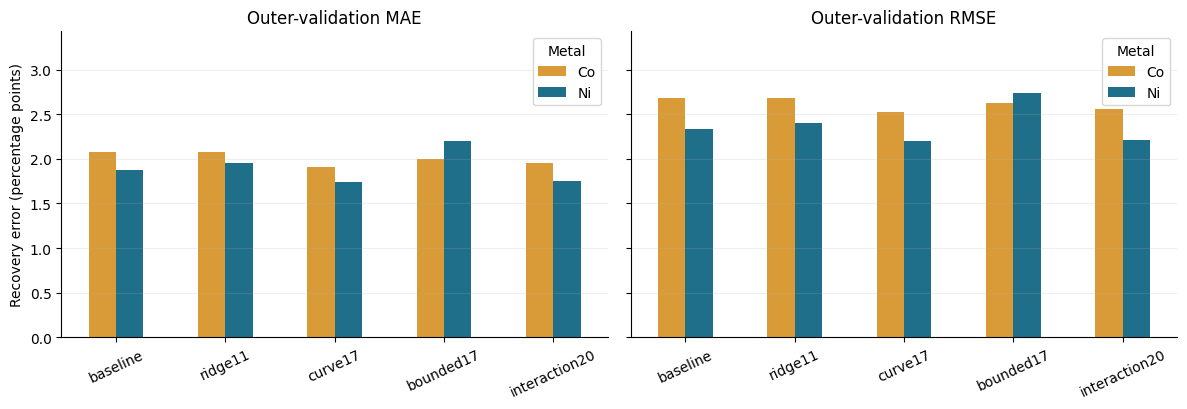

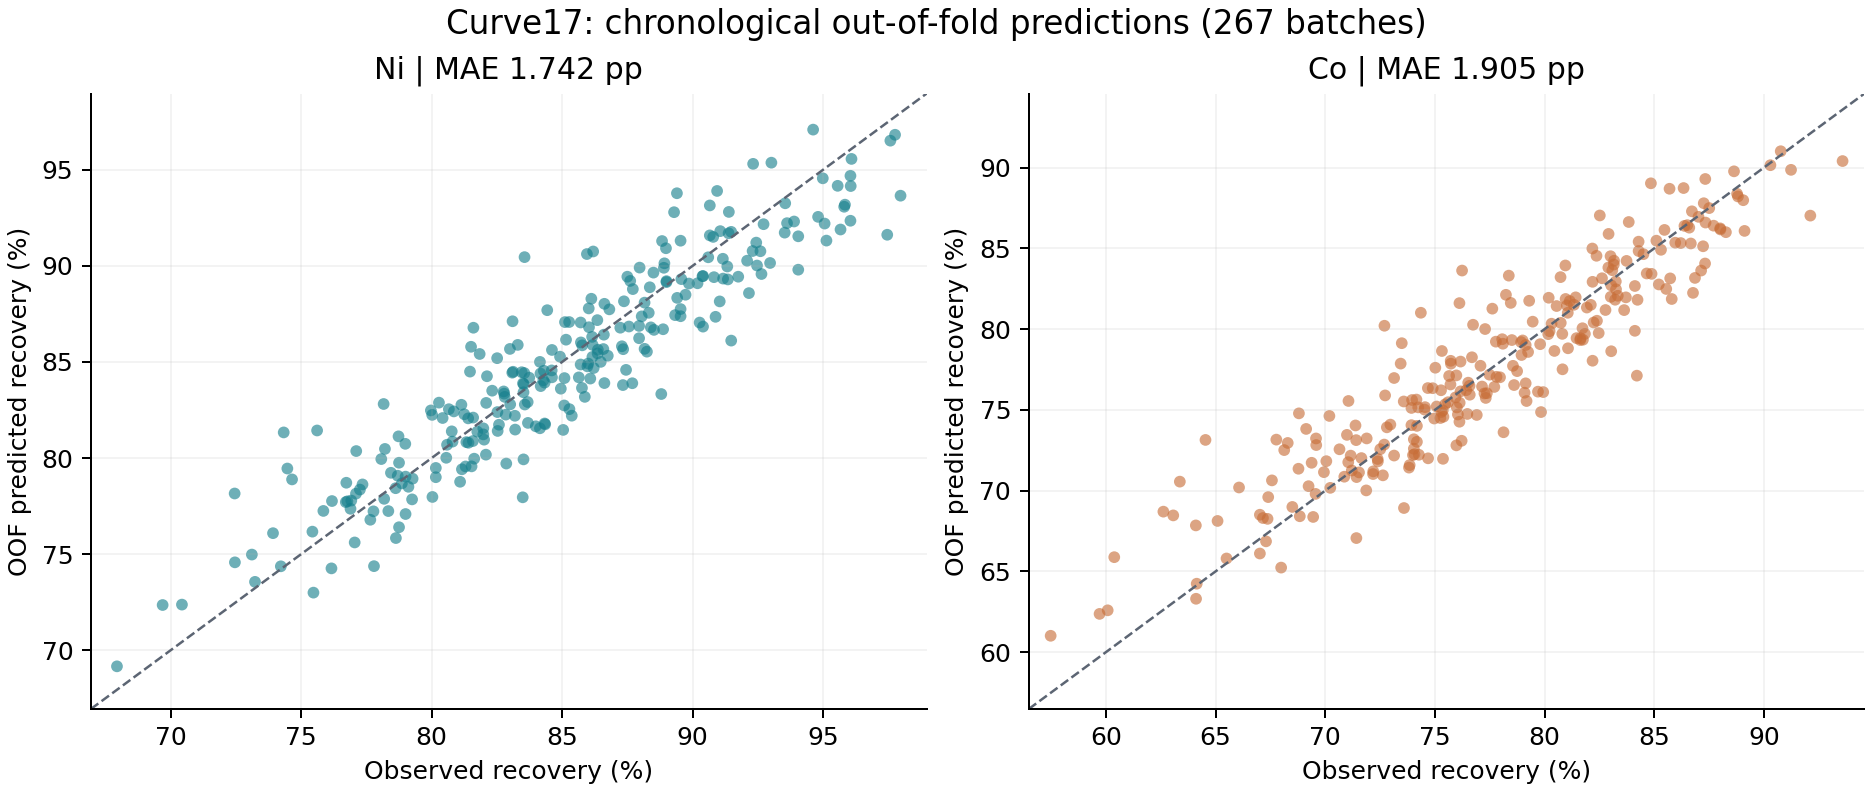

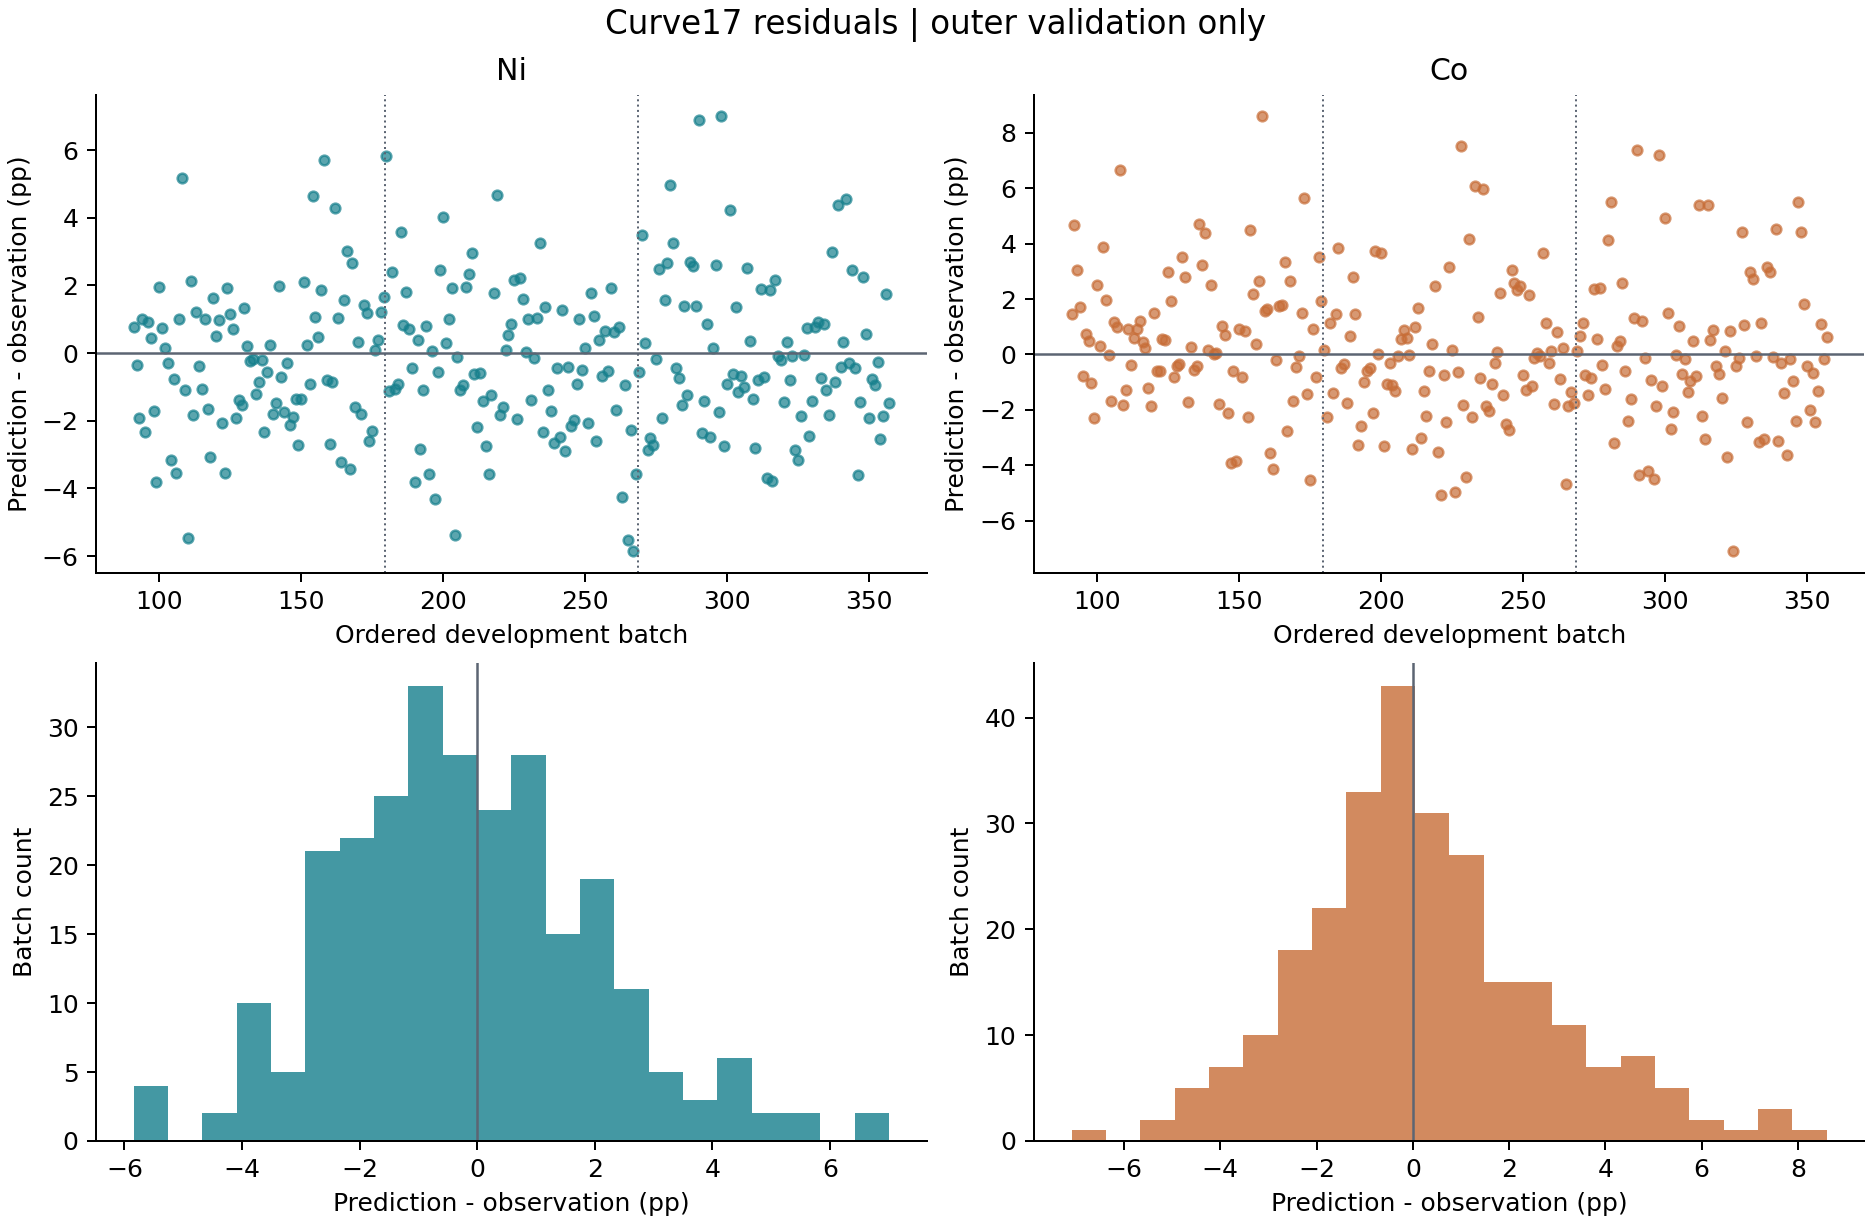

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, metric in zip(axes, ("MAE", "RMSE")):
    table = metrics.pivot(index="Candidate", columns="Metal", values=metric)
    table = table.reindex(["baseline", "ridge11", "curve17", "bounded17", "interaction20"])
    table.plot.bar(ax=ax, color=["#D99B37", "#1F6F8B"], rot=25)
    ax.set(title=f"Outer-validation {metric}", xlabel="", ylabel="Recovery error (percentage points)")
    ax.set_ylim(0, float(np.nanmax(table.to_numpy())) * 1.25)
    ax.grid(axis="y", alpha=.2)
fig.tight_layout()
display(fig)
plt.close(fig)
for name in ("predicted_vs_actual.png", "residuals.png"):
    display(Image(filename=str(RESULTS / name)))

## 3. 평균 오차와 목표 문턱은 다른 질문

curve17의 MAE 개선율은 비교 기준을 구분합니다. ridge11 대비는 6개 파생특성 묶음의 효과, baseline 대비는 이전 모델 대비의 효과입니다. 최대 절대오차와 목표 문턱의 오분류도 함께 확인합니다. 예측이 95%·90%를 넘었다고 실제 달성을 보장하지 않습니다.

In [6]:
improvements = []
for metal in ("Ni", "Co"):
    by_candidate = metrics.loc[metrics["Metal"].eq(metal)].set_index("Candidate")
    for comparator in ("ridge11", "baseline"):
        old = by_candidate.loc[comparator, "MAE"]
        new = by_candidate.loc["curve17", "MAE"]
        improvements.append({"Metal": metal, "Compared_with": comparator,
                             "MAE_reduction_percent": 100 * (old - new) / old})
display(pd.DataFrame(improvements))
target_classification = pd.read_csv(RESULTS / "target_classification.csv")
display(target_classification)

,Metal,Compared_with,MAE_reduction_percent
0,Ni,ridge11,10.904124
1,Ni,baseline,6.994070
2,Co,ridge11,8.393179
3,Co,baseline,8.393179


,population,target,N,TP,FP,FN,TN,predicted_pass,actual_pass,precision,recall,Ni_threshold,Co_threshold
0,all,Ni,267,3,3,11,250,6,14,0.50,0.214286,95,90
1,all,Co,267,3,0,2,262,3,5,1.00,0.600000,95,90
2,all,joint,267,1,1,1,264,2,2,0.50,0.500000,95,90
3,complete,Ni,113,1,1,5,106,2,6,0.50,0.166667,95,90
4,complete,Co,113,1,0,1,111,1,2,1.00,0.500000,95,90
5,complete,joint,113,0,1,1,111,1,1,0.00,0.000000,95,90
6,process_complete,Ni,213,3,1,10,199,4,13,0.75,0.230769,95,90
7,process_complete,Co,213,3,0,2,208,3,5,1.00,0.600000,95,90
8,process_complete,joint,213,1,1,1,210,2,2,0.50,0.500000,95,90


## 4. 검증 순열 중요도와 표준화 계수

원입력 11개 중 하나를 검증 자료에서 섞은 뒤, 그 입력에 의존하는 모든 파생특성을 다시 계산합니다. 검증 MAE 증가량이 큰 변수는 이 모델이 많이 의존하는 정보입니다. 각 fold 10회, seed 42를 사용합니다. 반복 간 표준편차는 신뢰구간이 아닙니다.

계수는 표준화된 17개 기저의 값이므로 원입력 순열 중요도와 직접 같은 척도로 비교하지 않습니다. 상관관계·교란 조합의 영향을 받으며 인과효과가 아닙니다. [공식 설명](https://scikit-learn.org/stable/modules/permutation_importance.html)

,Metal,Feature,MeanDeltaMAE,StdDeltaMAE,BaselineMAE,Folds,Repeats,RepeatsPerFold
20,Co,침출온도_C,2.040105,0.324033,1.905236,3,30,10
21,Co,침출시간_hr,1.250283,0.247682,1.905236,3,30,10
19,Co,황산투입량_L,1.241371,0.159045,1.905236,3,30,10
17,Co,Al_불순물_pct,0.907686,0.159211,1.905236,3,30,10
15,Co,Cu_불순물_pct,0.862448,0.157801,1.905236,3,30,10
18,Co,원료투입량_kg,0.792013,0.125672,1.905236,3,30,10
16,Co,Fe_불순물_pct,0.277095,0.108243,1.905236,3,30,10
11,Co,Ni_함량_pct,0.032877,0.057076,1.905236,3,30,10
14,Co,Mn_함량_pct,0.019144,0.024627,1.905236,3,30,10
13,Co,Li_함량_pct,0.014058,0.025452,1.905236,3,30,10


,Metal,Feature,FeatureIndex,Mean,Scale,StandardizedCoefficient,RawBasisCoefficient,SelectedAlpha,Intercept
0,Ni,Ni_함량_pct,0,18.882045,5.051889,0.156790,0.031036,0.1,85.036919
1,Ni,Co_함량_pct,1,8.194370,2.626670,-0.075843,-0.028874,0.1,85.036919
2,Ni,Li_함량_pct,2,3.832157,0.801927,-0.109726,-0.136828,0.1,85.036919
3,Ni,Mn_함량_pct,3,10.475952,1.979277,0.154137,0.077875,0.1,85.036919
4,Ni,Cu_불순물_pct,4,1.819188,1.121650,-1.114099,-0.993267,0.1,85.036919
5,Ni,Fe_불순물_pct,5,1.615028,1.108560,-1.103786,-0.995693,0.1,85.036919
6,Ni,Al_불순물_pct,6,2.567927,1.382230,-1.215453,-0.879342,0.1,85.036919
7,Ni,원료투입량_kg,7,142.416527,34.285514,-1.723151,-0.050259,0.1,85.036919
8,Ni,황산투입량_L,8,941.313725,306.775800,4.952862,0.016145,0.1,85.036919
9,Ni,침출온도_C,9,67.502101,15.154926,7.598090,0.501361,0.1,85.036919


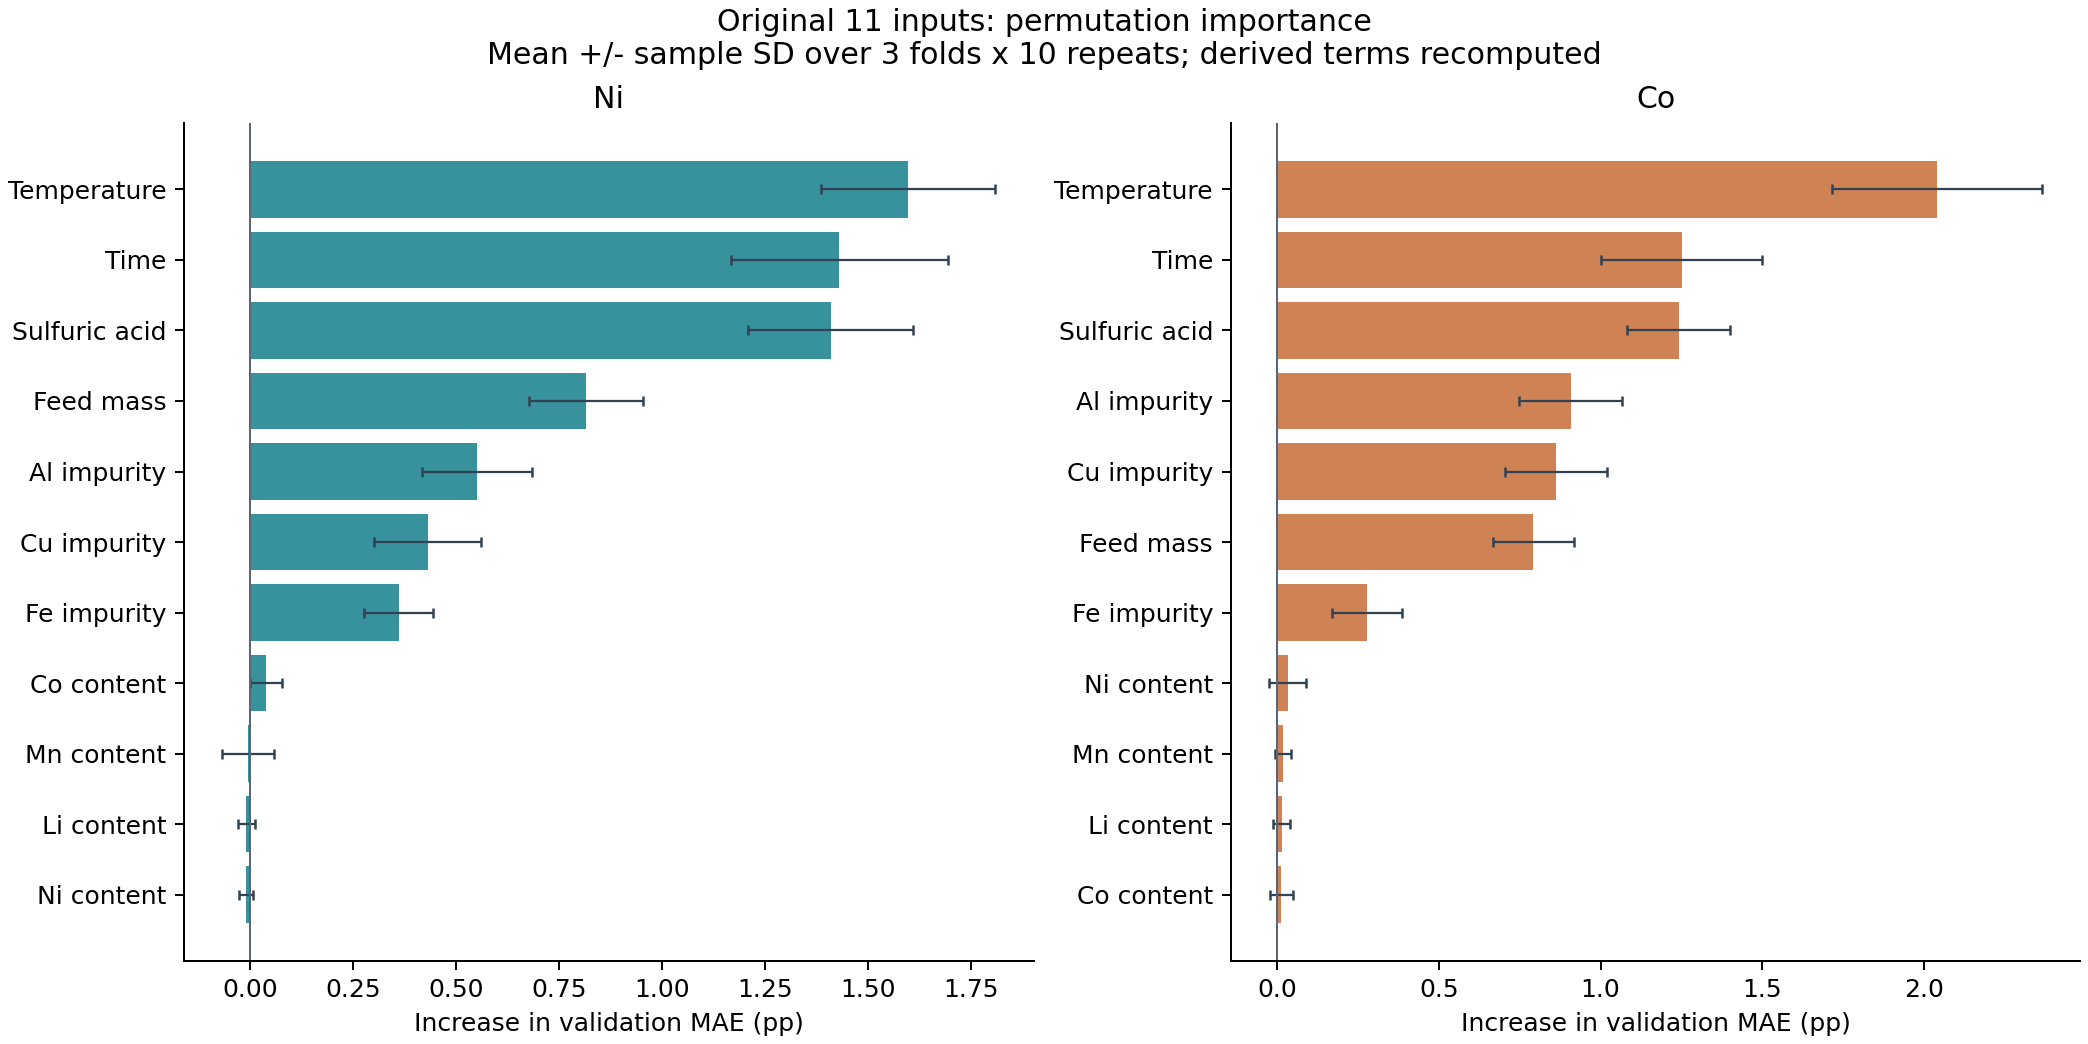

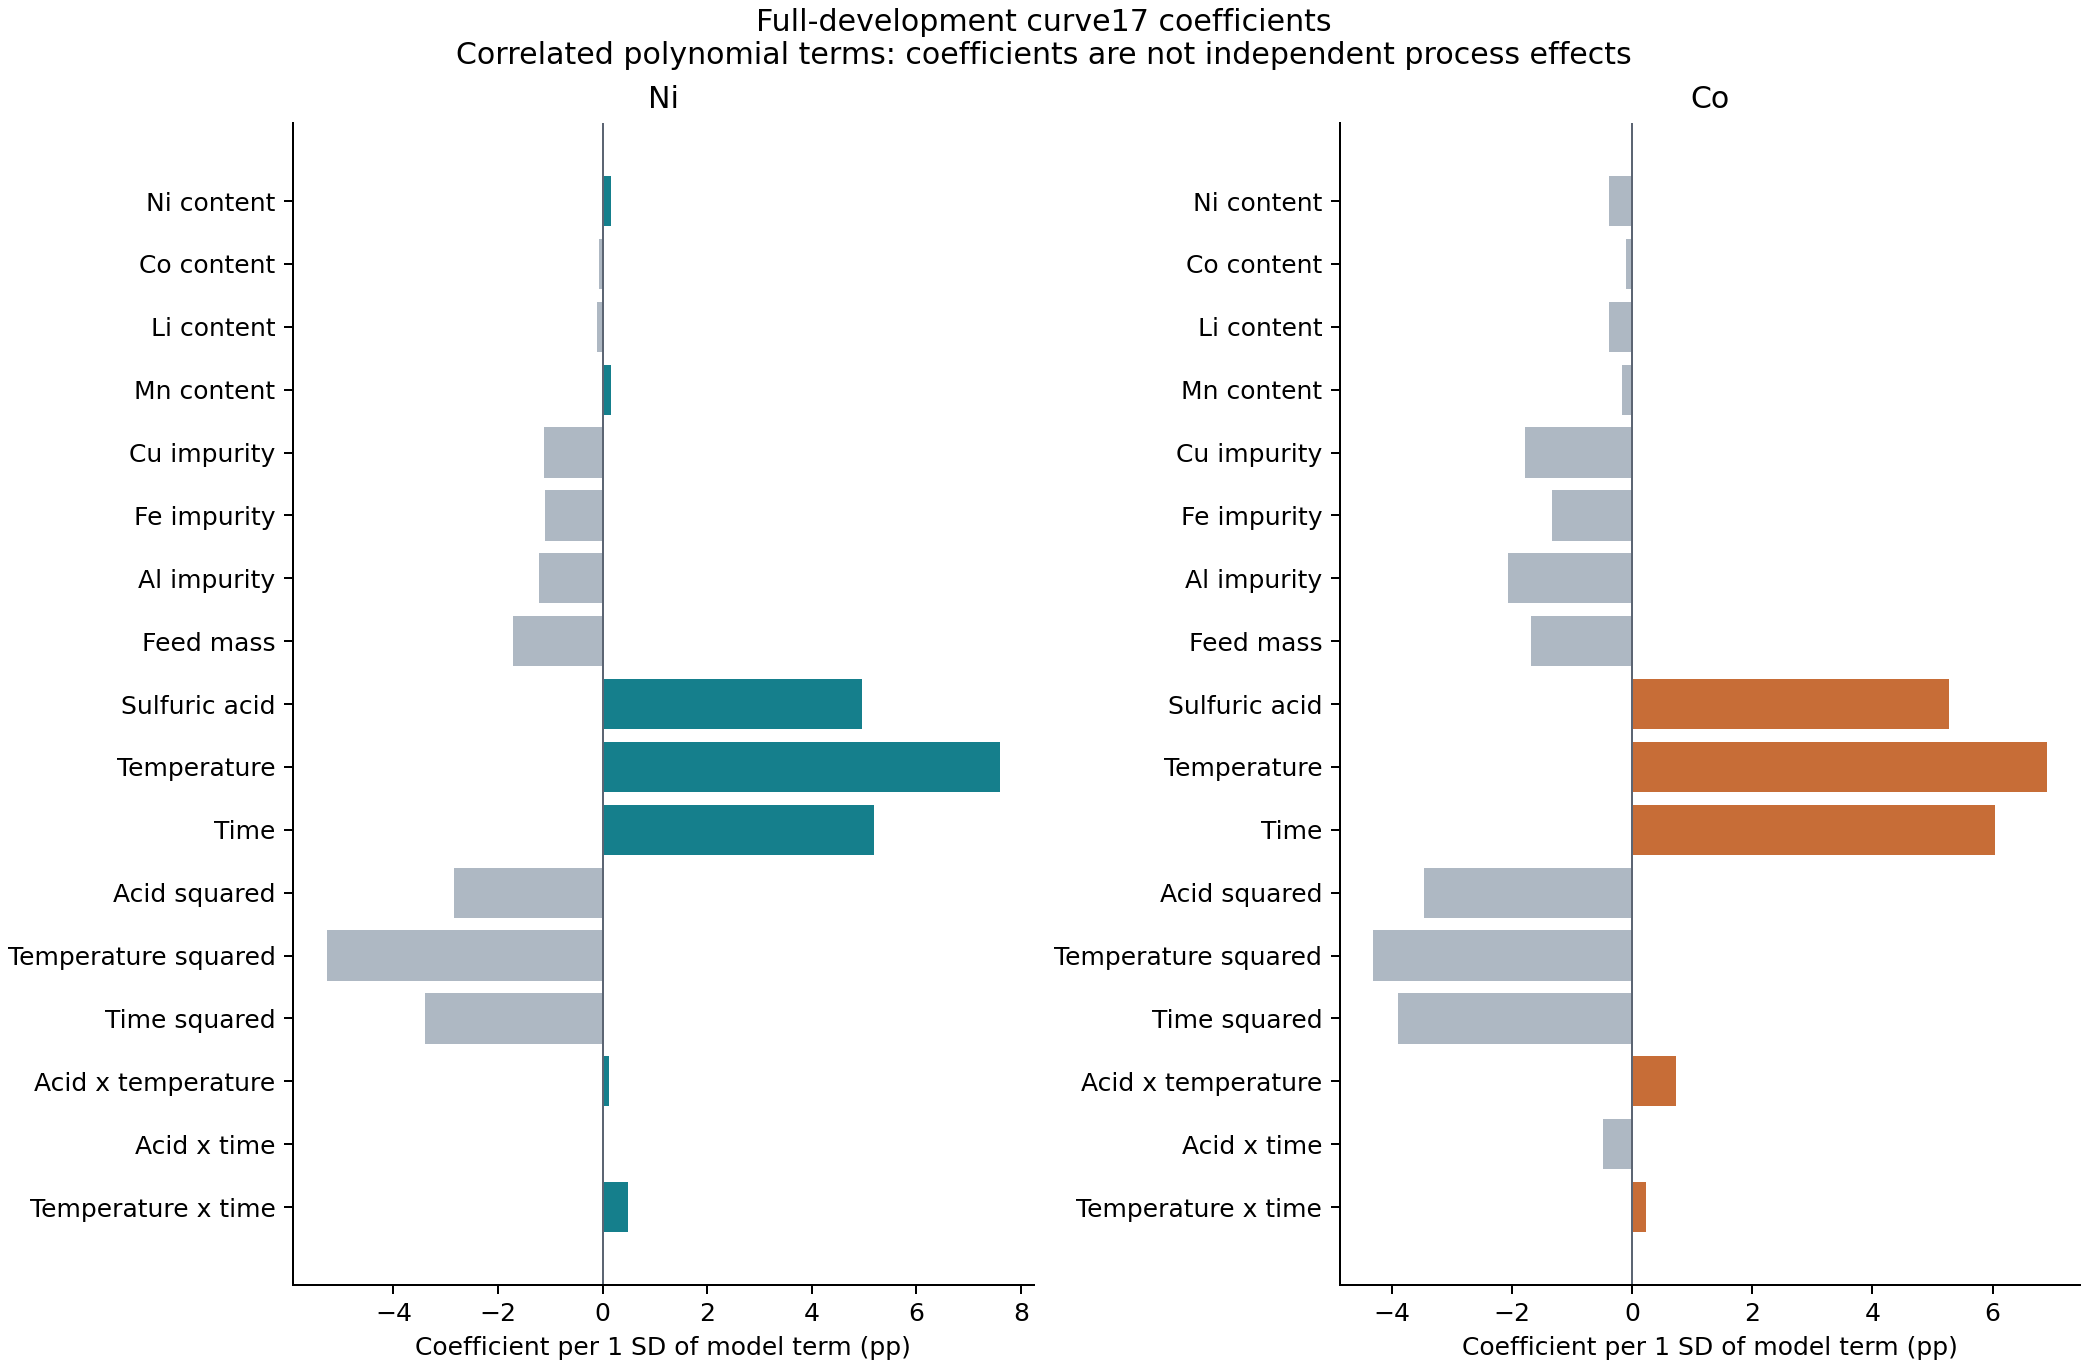

In [7]:
importance_result = run_importance()
IMPORTANCE = Path(importance_result["output_dir"])
permutation = pd.read_csv(IMPORTANCE / "permutation_importance.csv")
coefficients = pd.read_csv(IMPORTANCE / "standardized_coefficients.csv")
display(permutation.sort_values(["Metal", "MeanDeltaMAE"], ascending=[True, False]))
display(coefficients)
for name in ("permutation_importance.png", "standardized_coefficients.png"):
    display(Image(filename=str(IMPORTANCE / name)))

## 5. 개발 357행 재적합과 고정 추론의 수치 비교

아래는 학습을 재현하는 셀입니다. `refit_model.json`은 별도 결과이고, `Engine()`는 저장된 최종 모델을 읽습니다. 개발 전체 재적합의 선택 alpha와 완전 관측 개발 자료의 예측 차이를 확인합니다. 미세한 부동소수점 차이는 근거와 허용오차로 해석합니다.

In [8]:
refit_result = train_final()
REFIT = Path(refit_result["output_dir"])
refit = json.loads((REFIT / "refit_model.json").read_text(encoding="utf-8"))
display(pd.DataFrame([{"Metal": metal, "SelectedAlpha": alpha, "FitRows": refit["fit_rows"]}
                      for metal, alpha in refit["selected_alphas"].items()]))
parameters = np.asarray(refit["parameters"], dtype=float)
complete = load_clean_data().iloc[:357].dropna(subset=list(BASE))
x = complete[list(BASE)].to_numpy(float)
z = feature_matrix(x, "A17")
refit_prediction = np.column_stack([((z - p[:17]) / p[17:34]) @ p[34:51] + p[51] for p in parameters])
frozen = Engine()
frozen_prediction, distances = frozen.calculate(x)
display(pd.DataFrame({"Metal": ["Ni", "Co"],
                      "complete_development_rows": [len(x)] * 2,
                      "max_absolute_prediction_difference_pp": np.max(np.abs(refit_prediction - frozen_prediction), axis=0)}))
print("model_version:", refit["model_version"])
print("base_input_count:", len(refit["features"]))

model_version: YP-curve17-dev357-v2
base_input_count: 11


,Metal,SelectedAlpha,FitRows
0,Ni,0.1,357
1,Co,0.1,357


,Metal,complete_development_rows,max_absolute_prediction_difference_pp
0,Ni,151,5.684342e-14
1,Co,151,8.526513e-14


## 해석과 다음 단계

이 결과는 같은 개발 자료의 내부 비교와 재현입니다. 독립 실측 정확도·실제 운전 승인으로 확장하지 않습니다. 높은 목표 구간의 관측 수가 적고 원료-공정 상호작용을 검증하지 못한 한계가 남습니다.

03에서는 고정 예측을 공동·Ni·Co 목표에 적용합니다. [03 공정조건 탐색](03_optimization.ipynb) · [성능 비교 기준](../module2_prediction/reference/model_comparison_reference.json) · [예측 모듈 설명](../module2_prediction/README.md)